<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/ant%20colony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Delivery Locations:
Location_1: [51 92]
Location_2: [14 71]
Location_3: [60 20]
Location_4: [82 86]
Location_5: [74 74]
Location_6: [87 99]
Location_7: [23  2]
Location_8: [21 52]
Location_9: [ 1 87]
Location_10: [29 37]

Distance Matrix:
             Location_1  Location_2  Location_3  Location_4  Location_5  \
Location_1         0.00       42.54       72.56       31.58       29.21   
Location_2        42.54        0.00       68.68       69.63       60.07   
Location_3        72.56       68.68        0.00       69.57       55.79   
Location_4        31.58       69.63       69.57        0.00       14.42   
Location_5        29.21       60.07       55.79       14.42        0.00   
Location_6        36.67       78.19       83.49       13.93       28.18   
Location_7        94.25       69.58       41.15      102.65       88.23   
Location_8        50.00       20.25       50.45       69.84       57.38   
Location_9        50.25       20.62       89.27       81.01       74.15   
Location_10

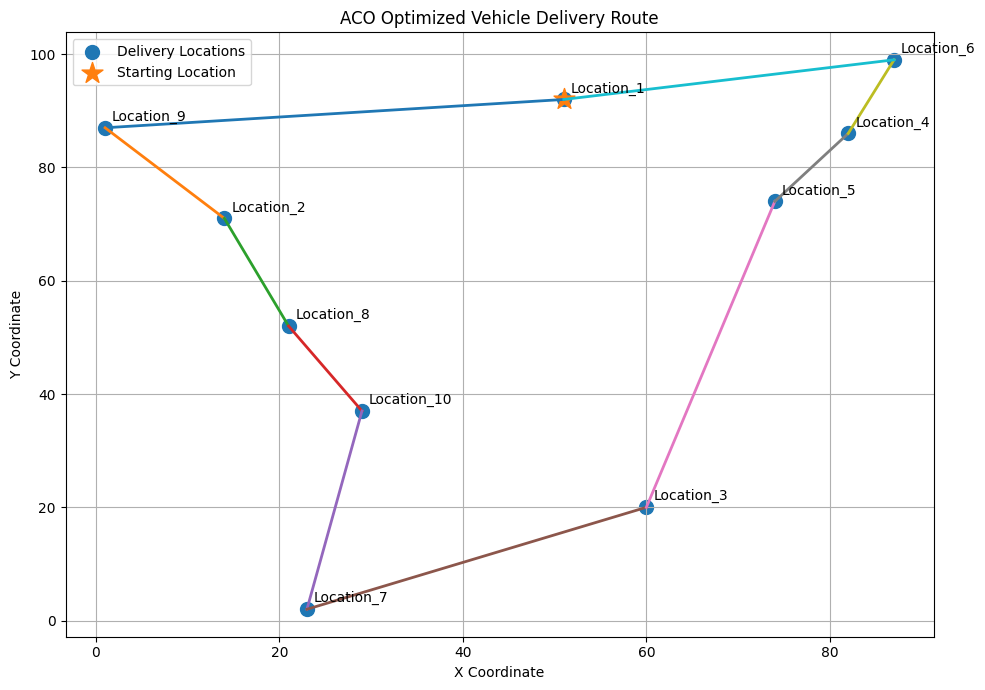

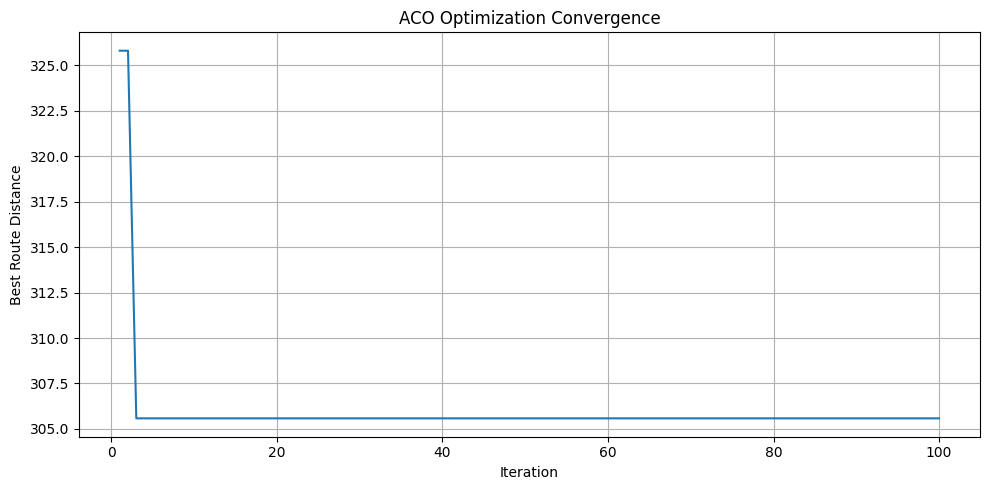

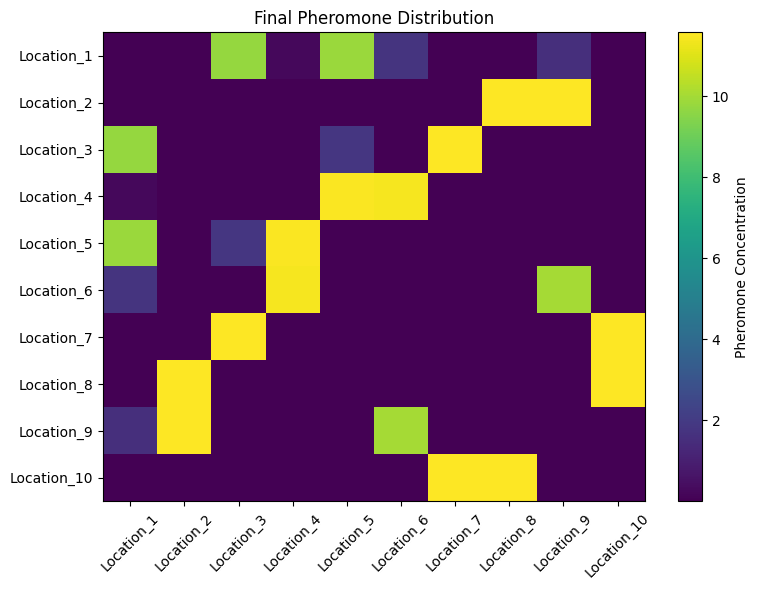


========== ROUTE DETAILS ==========

 Step From Location To Location  Travel Distance
    1    Location_1  Location_9            50.25
    2    Location_9  Location_2            20.62
    3    Location_2  Location_8            20.25
    4    Location_8 Location_10            17.00
    5   Location_10  Location_7            35.51
    6    Location_7  Location_3            41.15
    7    Location_3  Location_5            55.79
    8    Location_5  Location_4            14.42
    9    Location_4  Location_6            13.93
   10    Location_6  Location_1            36.67

Excel report generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT EXECUTION COMPLETED SUCCESSFULLY!


In [1]:

# ============================================================
# ANT COLONY OPTIMIZATION (ACO)
# VEHICLE ROUTE OPTIMIZATION
# GOOGLE COLAB IMPLEMENTATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from google.colab import files

# ------------------------------------------------------------
# 1. INITIALIZATION
# ------------------------------------------------------------

random.seed(42)
np.random.seed(42)

# Generate 10 delivery locations
NUM_CITIES = 10

cities = np.random.randint(
    0, 100,
    size=(NUM_CITIES, 2)
)

city_names = [
    f"Location_{i+1}"
    for i in range(NUM_CITIES)
]

START_CITY = 0

print("Delivery Locations:")
for i, city in enumerate(cities):
    print(f"{city_names[i]}: {city}")


# ------------------------------------------------------------
# 2. CALCULATE DISTANCE MATRIX
# ------------------------------------------------------------

distance_matrix = np.zeros(
    (NUM_CITIES, NUM_CITIES)
)

for i in range(NUM_CITIES):
    for j in range(NUM_CITIES):

        distance_matrix[i][j] = np.linalg.norm(
            cities[i] - cities[j]
        )

print("\nDistance Matrix:")
print(pd.DataFrame(
    distance_matrix,
    index=city_names,
    columns=city_names
).round(2))


# ------------------------------------------------------------
# 3. ACO PARAMETERS
# ------------------------------------------------------------

NUM_ANTS = 20
NUM_ITERATIONS = 100

ALPHA = 1.0
BETA = 2.0

EVAPORATION_RATE = 0.5

Q = 100

INITIAL_PHEROMONE = 1.0


# ------------------------------------------------------------
# 4. INITIALIZE PHEROMONE MATRIX
# ------------------------------------------------------------

pheromone = np.ones(
    (NUM_CITIES, NUM_CITIES)
) * INITIAL_PHEROMONE

# Heuristic information: inverse of distance
heuristic = 1 / (
    distance_matrix + 1e-10
)

np.fill_diagonal(heuristic, 0)


# ------------------------------------------------------------
# 5. ROUTE DISTANCE CALCULATION
# ------------------------------------------------------------

def calculate_route_distance(route):

    total_distance = 0

    for i in range(len(route) - 1):

        total_distance += distance_matrix[
            route[i], route[i + 1]
        ]

    # Return to starting city
    total_distance += distance_matrix[
        route[-1], route[0]
    ]

    return total_distance


# ------------------------------------------------------------
# 6. ANT ROUTE CONSTRUCTION
# ------------------------------------------------------------

def construct_route():

    route = [START_CITY]

    unvisited = set(
        range(NUM_CITIES)
    )

    unvisited.remove(START_CITY)

    while unvisited:

        current_city = route[-1]

        candidates = list(unvisited)

        # Calculate transition probabilities
        probabilities = []

        for next_city in candidates:

            probability = (
                (pheromone[current_city, next_city] ** ALPHA)
                *
                (heuristic[current_city, next_city] ** BETA)
            )

            probabilities.append(probability)

        probabilities = np.array(probabilities)

        # Normalize probabilities
        total = probabilities.sum()

        if total == 0 or not np.isfinite(total):

            probabilities = np.ones(
                len(candidates)
            ) / len(candidates)

        else:

            probabilities = probabilities / total

        # Select next city
        next_city = np.random.choice(
            candidates,
            p=probabilities
        )

        route.append(next_city)

        unvisited.remove(next_city)

    return route


# ------------------------------------------------------------
# 7. PHEROMONE UPDATE
# ------------------------------------------------------------

def update_pheromone(all_routes, all_distances):

    global pheromone

    # Evaporation
    pheromone *= (
        1 - EVAPORATION_RATE
    )

    # Deposit pheromone on routes
    for route, distance in zip(
        all_routes,
        all_distances
    ):

        deposit = Q / distance

        for i in range(NUM_CITIES - 1):

            city1 = route[i]
            city2 = route[i + 1]

            pheromone[city1, city2] += deposit

            pheromone[city2, city1] += deposit

        # Closing edge: last city back to starting city
        last_city = route[-1]
        first_city = route[0]

        pheromone[last_city, first_city] += deposit
        pheromone[first_city, last_city] += deposit

    # Keep pheromone values within numerical limits
    pheromone[:] = np.clip(
        pheromone,
        1e-8,
        1e6
    )


# ------------------------------------------------------------
# 8. ANT COLONY OPTIMIZATION
# ------------------------------------------------------------

def ant_colony_optimization():

    global pheromone

    best_route = None
    best_distance = float("inf")

    convergence_history = []

    for iteration in range(NUM_ITERATIONS):

        all_routes = []
        all_distances = []

        # Each ant creates one route
        for ant in range(NUM_ANTS):

            route = construct_route()

            distance = calculate_route_distance(
                route
            )

            all_routes.append(route)
            all_distances.append(distance)

            # Update best solution
            if distance < best_distance:

                best_distance = distance
                best_route = route.copy()

        # Update pheromone trails
        update_pheromone(
            all_routes,
            all_distances
        )

        convergence_history.append(
            best_distance
        )

        if iteration % 10 == 0:

            print(
                f"Iteration {iteration + 1}: "
                f"Best Distance = {best_distance:.2f}"
            )

    return (
        best_route,
        best_distance,
        convergence_history
    )


# ------------------------------------------------------------
# 9. EXECUTE ACO
# ------------------------------------------------------------

print("\nStarting Ant Colony Optimization...\n")

best_route, best_distance, history = (
    ant_colony_optimization()
)

print("\nACO Optimization Completed!")


# ------------------------------------------------------------
# 10. DISPLAY OPTIMIZED ROUTE
# ------------------------------------------------------------

route_names = [
    city_names[city]
    for city in best_route
]

route_names.append(
    city_names[START_CITY]
)

print("\n========== OPTIMIZED VEHICLE ROUTE ==========\n")

print(" -> ".join(route_names))

print(
    "\nMinimum Route Distance:",
    round(best_distance, 2)
)


# ------------------------------------------------------------
# 11. ROUTE VALIDATION
# ------------------------------------------------------------

def validate_route(route):

    visited = set(route)

    valid = (
        len(route) == NUM_CITIES
        and len(visited) == NUM_CITIES
        and START_CITY == route[0]
        and all(
            0 <= city < NUM_CITIES
            for city in route
        )
    )

    if valid:

        print(
            "SUCCESS: Every location is visited exactly once."
        )

        print(
            "SUCCESS: Route returns to the starting location."
        )

    else:

        print("ERROR: Invalid route generated.")

    return valid


print("\n========== ROUTE VALIDATION ==========\n")

validation_result = validate_route(best_route)


# ------------------------------------------------------------
# 12. VISUALIZE OPTIMIZED ROUTE
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

# Plot all locations
plt.scatter(
    cities[:, 0],
    cities[:, 1],
    s=100,
    label="Delivery Locations"
)

# Label cities
for i, (x, y) in enumerate(cities):

    plt.annotate(
        city_names[i],
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Draw optimized route
route_with_return = (
    best_route + [START_CITY]
)

for i in range(len(route_with_return) - 1):

    city1 = route_with_return[i]
    city2 = route_with_return[i + 1]

    plt.plot(
        [cities[city1][0], cities[city2][0]],
        [cities[city1][1], cities[city2][1]],
        linestyle="-",
        linewidth=2
    )

# Highlight starting location
plt.scatter(
    cities[START_CITY][0],
    cities[START_CITY][1],
    s=250,
    marker="*",
    label="Starting Location"
)

plt.title("ACO Optimized Vehicle Delivery Route")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. CONVERGENCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, NUM_ITERATIONS + 1),
    history
)

plt.title("ACO Optimization Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Route Distance")
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. PHEROMONE MATRIX VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.imshow(
    pheromone,
    interpolation="nearest",
    aspect="auto"
)

plt.colorbar(
    label="Pheromone Concentration"
)

plt.xticks(
    range(NUM_CITIES),
    city_names,
    rotation=45
)

plt.yticks(
    range(NUM_CITIES),
    city_names
)

plt.title("Final Pheromone Distribution")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. CREATE ROUTE DETAILS TABLE
# ------------------------------------------------------------

route_details = []

for i in range(len(best_route)):

    current_city = best_route[i]

    next_city = best_route[
        (i + 1) % NUM_CITIES
    ]

    distance = distance_matrix[
        current_city,
        next_city
    ]

    route_details.append({

        "Step": i + 1,

        "From Location": city_names[current_city],

        "To Location": city_names[next_city],

        "Travel Distance": round(
            distance, 2
        )

    })

route_df = pd.DataFrame(
    route_details
)

print("\n========== ROUTE DETAILS ==========\n")

print(
    route_df.to_string(index=False)
)


# ------------------------------------------------------------
# 16. EXPORT RESULTS TO EXCEL
# ------------------------------------------------------------

convergence_df = pd.DataFrame({

    "Iteration": range(
        1,
        NUM_ITERATIONS + 1
    ),

    "Best Route Distance": history

})

location_df = pd.DataFrame({

    "Location": city_names,

    "X Coordinate": cities[:, 0],

    "Y Coordinate": cities[:, 1]

})

with pd.ExcelWriter(
    "ACO_Vehicle_Route_Optimization.xlsx"
) as writer:

    route_df.to_excel(
        writer,
        sheet_name="Optimized Route",
        index=False
    )

    convergence_df.to_excel(
        writer,
        sheet_name="Convergence",
        index=False
    )

    location_df.to_excel(
        writer,
        sheet_name="Locations",
        index=False
    )

print("\nExcel report generated successfully!")


# ------------------------------------------------------------
# 17. DOWNLOAD EXCEL REPORT
# ------------------------------------------------------------

files.download(
    "ACO_Vehicle_Route_Optimization.xlsx"
)

print("\nPROJECT EXECUTION COMPLETED SUCCESSFULLY!")
